# Spoken Audio Grammar Scoring: Solution Notebook

This notebook develops a model for predicting the grammar score of a spoken audio clip. I started with simple baselines and gradually tested different speech representations and regression models before settling on the final ensemble.

**Final model:** a 50/50 ensemble of frozen Whisper-medium (Layer 24) and Whisper-large-v3 (Layer 32) embeddings. Each embedding is pooled across the valid audio frames, standardized, and passed to a Ridge regressor with `alpha=1000`. The two predictions are then averaged and clipped to the valid score range of 0 to 5.

The final model is trained using the 732 speech clips in the training set. The remaining 37 training clips are treated separately by the noise rule described later in the notebook.

In [6]:
# Setup. Run once; skips packages that are already installed.
import importlib.util, subprocess, sys
needed = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy",
          "sklearn": "scikit-learn", "soundfile": "soundfile",
          "matplotlib": "matplotlib", "transformers": "transformers==4.57.6"}
missing = [pip for mod, pip in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
# PyTorch is installed separately because the build depends on your CUDA version:
#   pip install torch==2.7.1 --index-url https://download.pytorch.org/whl/cu118


In [8]:
# -----------------------------------------------------------------------------
# Check / Build Embeddings Cache
# Checks for existing .npz files; if missing, downloads models & extracts features.
# -----------------------------------------------------------------------------

import os
import torch
import soundfile as sf
import numpy as np
import pandas as pd
from transformers import AutoFeatureExtractor, WhisperModel

# Ensure target cache directory exists
CACHE_DIR = os.path.join("cache", "embeddings")
os.makedirs(CACHE_DIR, exist_ok=True)

# Device configuration (GPU if available, otherwise CPU)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


# -----------------------------------------------------------------------------
# Load metadata
# -----------------------------------------------------------------------------

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

# Keep only speech clips for embedding extraction.
# The 37 label-0 clips are acoustic noise and are handled separately.
speech_train_df = (
    train_df[train_df["label"] > 0.0]
    .copy()
    .reset_index(drop=True)
)

train_filenames = speech_train_df["filename"].values
test_filenames = test_df["filename"].values

print(f"Speech training clips: {len(train_filenames)}")
print(f"Test clips: {len(test_filenames)}")


# -----------------------------------------------------------------------------
# Extraction helper
# Valid-frame, window-weighted mean pooling over 30-second chunks
# -----------------------------------------------------------------------------

def extract_whisper_clip_layers(
    audio_path,
    feature_extractor,
    encoder,
    target_layers,
    dev
):
    data, sr = sf.read(audio_path)

    if len(data.shape) > 1:
        data = data.mean(axis=1)  # downmix to mono if stereo

    tot_samples = len(data)
    win_samples = 30 * sr
    n_windows = int(np.ceil(tot_samples / win_samples))

    layer_embs = {l: [] for l in target_layers}
    weights = []

    for w in range(n_windows):
        chunk = data[
            w * win_samples:
            min((w + 1) * win_samples, tot_samples)
        ]

        chunk_sec = len(chunk) / sr

        inputs = feature_extractor(
            chunk,
            sampling_rate=sr,
            return_tensors="pt"
        ).input_features

        if dev.type == "cuda":
            inputs = inputs.half()

        inputs = inputs.to(dev)

        with torch.no_grad():
            out = encoder(
                inputs,
                output_hidden_states=True
            )

            # Number of valid Whisper frames for this chunk.
            # A full 30-second window contains 1500 frames.
            v_len = min(
                1500,
                int(round(chunk_sec / 30.0 * 1500))
            )

            for l in target_layers:
                hid = out.hidden_states[l][0]

                # Pool only valid frames, excluding padded frames.
                pool = (
                    hid[:v_len]
                    .mean(dim=0)
                    .cpu()
                    .numpy()
                )

                layer_embs[l].append(pool)

            # Weight each window by the number of valid frames.
            weights.append(v_len)

    tot_weight = sum(weights)

    return {
        l: sum(
            e * (w / tot_weight)
            for e, w in zip(layer_embs[l], weights)
        )
        for l in target_layers
    }


# -----------------------------------------------------------------------------
# Model extraction specifications
# -----------------------------------------------------------------------------

models_to_process = [
    {
        "cache_filename": "whisper_medium_layers.npz",
        "hf_model_id": "openai/whisper-medium",
        "layers": [4, 8, 12, 16, 20, 22, 23, 24],
    },
    {
        "cache_filename": "whisper_large_v3_layers.npz",
        "hf_model_id": "openai/whisper-large-v3",
        "layers": [5, 10, 16, 22, 28, 29, 30, 31, 32],
    },
    {
        "cache_filename": "whisper_small_layers.npz",
        "hf_model_id": "openai/whisper-small",
        "layers": [3, 6, 9, 12],
    },
]


# -----------------------------------------------------------------------------
# Process each model
# -----------------------------------------------------------------------------

for m_spec in models_to_process:

    cache_path = os.path.join(
        CACHE_DIR,
        m_spec["cache_filename"]
    )

    # Reuse an existing cache instead of extracting again.
    if os.path.exists(cache_path):
        print(
            f"[FOUND] {m_spec['cache_filename']} exists in cache. "
            "Skipping download & extraction."
        )
        continue

    print(f"[MISSING] {m_spec['cache_filename']} not found.")
    print(
        f"Downloading {m_spec['hf_model_id']} "
        "from HuggingFace..."
    )

    # Load feature extractor and Whisper model.
    fe = AutoFeatureExtractor.from_pretrained(
        m_spec["hf_model_id"]
    )

    model = WhisperModel.from_pretrained(
        m_spec["hf_model_id"]
    )

    if device.type == "cuda":
        encoder = model.encoder.half().to(device)
    else:
        encoder = model.encoder.float().to(device)

    encoder.eval()

    cache_dict = {}


    # -------------------------------------------------------------------------
    # Extract training clips
    # -------------------------------------------------------------------------

    print(
        f"Extracting features for "
        f"{len(train_filenames)} training clips..."
    )

    for fn in train_filenames:

        audio_file = os.path.join(
            DATA_DIR,
            "train",
            fn
        )

        embs_by_layer = extract_whisper_clip_layers(
            audio_file,
            fe,
            encoder,
            m_spec["layers"],
            device
        )

        for l, emb in embs_by_layer.items():
            cache_dict[
                f"train/{fn}/layer_{l}"
            ] = emb


    # -------------------------------------------------------------------------
    # Extract test clips
    # -------------------------------------------------------------------------

    print(
        f"Extracting features for "
        f"{len(test_filenames)} test clips..."
    )

    for fn in test_filenames:

        audio_file = os.path.join(
            DATA_DIR,
            "test",
            fn
        )

        embs_by_layer = extract_whisper_clip_layers(
            audio_file,
            fe,
            encoder,
            m_spec["layers"],
            device
        )

        for l, emb in embs_by_layer.items():
            cache_dict[
                f"test/{fn}/layer_{l}"
            ] = emb


    # -------------------------------------------------------------------------
    # Save compressed embeddings
    # -------------------------------------------------------------------------

    print(
        f"Saving extracted embeddings to {cache_path}..."
    )

    np.savez_compressed(
        cache_path,
        **cache_dict
    )

    print(
        f"[DONE] Saved {len(cache_dict)} embedding keys."
    )


    # -------------------------------------------------------------------------
    # Free GPU / CPU memory before loading the next model
    # -------------------------------------------------------------------------

    del encoder
    del model
    del fe

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print("\nAll model caches are verified and ready.")

Using device: cpu
Speech training clips: 732
Test clips: 216
[FOUND] whisper_medium_layers.npz exists in cache. Skipping download & extraction.
[FOUND] whisper_large_v3_layers.npz exists in cache. Skipping download & extraction.
[FOUND] whisper_small_layers.npz exists in cache. Skipping download & extraction.

All model caches are verified and ready.


In [9]:
# Library imports
import os
import sys
import json
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from scipy.stats import pearsonr
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import StratifiedGroupKFold
import torch
import transformers

DATA_DIR = "data"
CACHE_DIR = "cache/embeddings"
REPORTS_DIR = "reports"

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("Environment:")
print(f"  Python: {sys.version.split()[0]}")
print(f"  PyTorch: {torch.__version__} | CUDA: {torch.cuda.is_available()}")
print(f"  Transformers: {transformers.__version__}")


Environment:
  Python: 3.10.18
  PyTorch: 2.11.0+cpu | CUDA: False
  Transformers: 4.57.6


## 1. Problem and approach

The goal is to predict a grammar score from a spoken audio clip. The training set contains 769 clips and the test set contains 216 clips.

I first tested text-based and handcrafted features, including MiniLM embeddings, fluency measures, and GPT-2 surprisal. These features did not improve the results enough to justify adding them to the final model, so I focused on the speech signal itself.

For the final approach, I use frozen Whisper-medium Layer 24 and Whisper-large-v3 Layer 32 embeddings. Each audio file is processed in 30-second windows, and only the valid audio frames are used when pooling the embeddings. The resulting features are standardized and used to train Ridge regressors with `alpha=1000`. The predictions from the two models are then averaged 50/50.

This gives a simple model while still making use of pretrained speech representations.

## 2. Data checks

Before training, I checked the dataset size, audio durations, label distribution, filename overlap, and basic acoustic properties.

One important finding was that 212 filenames appear in both train and test, but the corresponding audio files are different. I therefore do not use filenames or IDs as model features. IDs are only used to create validation groups.

There are also 37 training clips with a target score of `0.0`. These files contain broadband acoustic noise rather than speech that can be meaningfully scored for grammar. Including them in the speech regression would affect the feature scaling, so I handle these clips separately.

For the audio checks, I calculated Zero Crossing Rate (ZCR), Spectral Flatness, and RMS energy. A simple threshold-based detector, selected using only the training data, identifies all 37 of these noise clips and does not flag any of the test clips.

In [10]:
# 2.1 Load metadata and measure audio durations
train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

print(f"Dataset sizes:")
print(f"  Train: {len(train_df)} clips")
print(f"  Test:  {len(test_df)} clips")

shared_names = set(train_df["filename"]).intersection(set(test_df["filename"]))
print(f"  Shared filenames between train and test: {len(shared_names)} (different audio content)")

def get_audio_info(rel_path):
    data, sr = sf.read(rel_path)
    if len(data.shape) > 1:
        data = data.mean(axis=1)
    duration = len(data) / sr
    rms = np.sqrt(np.mean(data**2))
    # Zero crossing rate
    zcr = np.mean(np.abs(np.diff(np.sign(data)))) / 2.0
    # Spectral flatness (power spectrum)
    n_fft = 2048
    if len(data) >= n_fft:
        spec = np.abs(np.fft.rfft(data[:n_fft * 10].reshape(-1, n_fft), axis=1))**2 + 1e-12
        geom = np.exp(np.mean(np.log(spec), axis=1))
        arith = np.mean(spec, axis=1)
        flatness = float(np.mean(geom / arith))
    else:
        flatness = 0.0
    return duration, rms, zcr, flatness

train_stats = [get_audio_info(os.path.join(DATA_DIR, "train", fn)) for fn in train_df["filename"]]
train_df["duration"] = [s[0] for s in train_stats]
train_df["rms"] = [s[1] for s in train_stats]
train_df["zcr"] = [s[2] for s in train_stats]
train_df["flatness"] = [s[3] for s in train_stats]

test_stats = [get_audio_info(os.path.join(DATA_DIR, "test", fn)) for fn in test_df["filename"]]
test_df["duration"] = [s[0] for s in test_stats]
test_df["rms"] = [s[1] for s in test_stats]
test_df["zcr"] = [s[2] for s in test_stats]
test_df["flatness"] = [s[3] for s in test_stats]

display(pd.DataFrame([
    {"Split": "Train", "Clips": len(train_df), "Min Dur": f"{train_df['duration'].min():.2f}s", "Median Dur": f"{train_df['duration'].median():.2f}s", "Max Dur": f"{train_df['duration'].max():.2f}s"},
    {"Split": "Test", "Clips": len(test_df), "Min Dur": f"{test_df['duration'].min():.2f}s", "Median Dur": f"{test_df['duration'].median():.2f}s", "Max Dur": f"{test_df['duration'].max():.2f}s"},
]))


Dataset sizes:
  Train: 769 clips
  Test:  216 clips
  Shared filenames between train and test: 212 (different audio content)


,Split,Clips,Min Dur,Median Dur,Max Dur
0,Train,769,20.06s,60.07s,61.04s
1,Test,216,6.48s,45.06s,61.03s


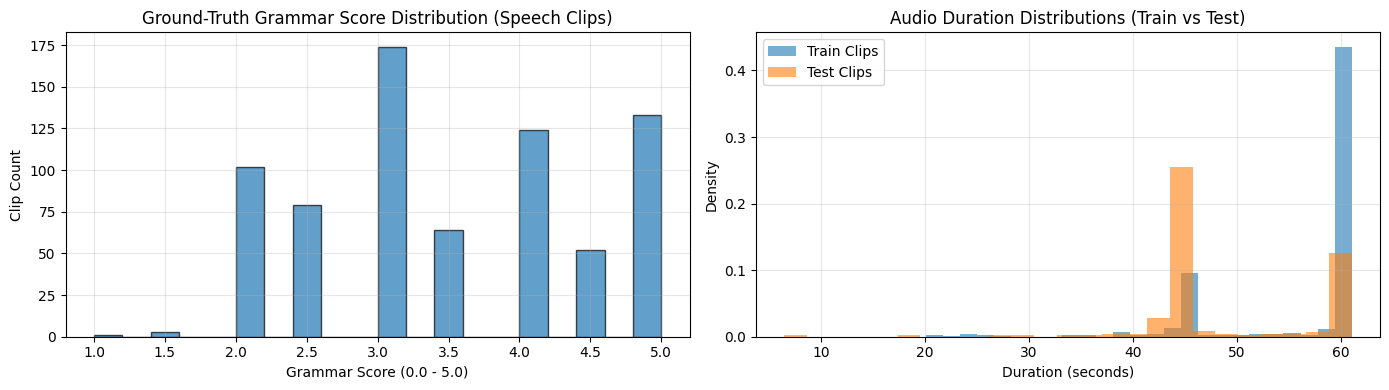

In [11]:
# 2.2 Exploratory distributions: Labels and Durations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Graph 1: Target score distribution
ax1.hist(train_df[train_df["label"] > 0]["label"], bins=20, color="tab:blue", edgecolor="black", alpha=0.7)
ax1.set_title("Ground-Truth Grammar Score Distribution (Speech Clips)")
ax1.set_xlabel("Grammar Score (0.0 - 5.0)")
ax1.set_ylabel("Clip Count")
ax1.grid(True, alpha=0.3)

# Graph 2: Audio duration comparison
ax2.hist(train_df["duration"], bins=25, alpha=0.6, label="Train Clips", color="tab:blue", density=True)
ax2.hist(test_df["duration"], bins=25, alpha=0.6, label="Test Clips", color="tab:orange", density=True)
ax2.set_title("Audio Duration Distributions (Train vs Test)")
ax2.set_xlabel("Duration (seconds)")
ax2.set_ylabel("Density")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


,Subset,Total,Flagged as Noise
0,Train (37 label 0.0 clips),37,37
1,Test (216 evaluation clips),216,0


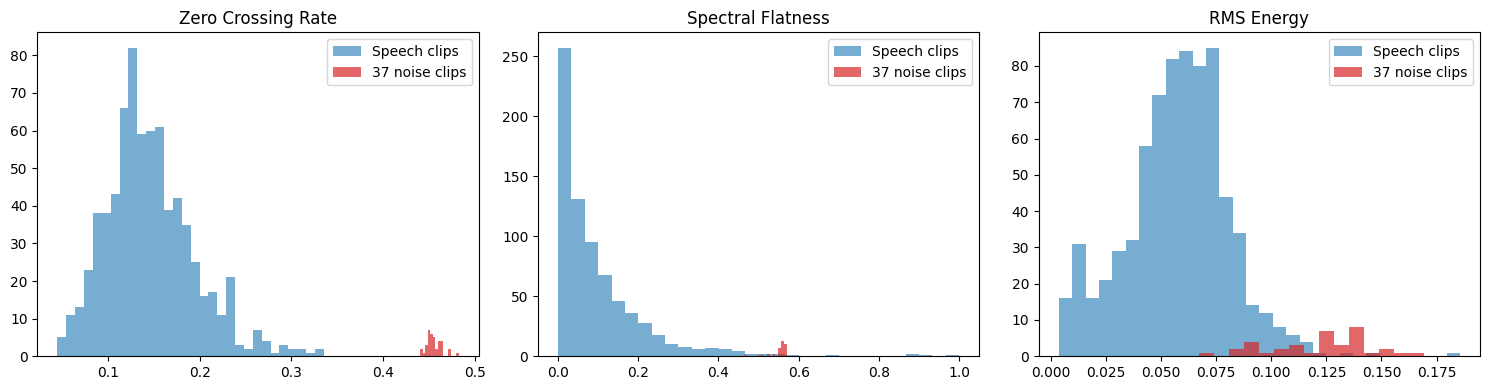

In [12]:
# 2.3 Acoustic noise detector
zero_clips = train_df[train_df["label"] == 0.0]
speech_train_df = train_df[train_df["label"] > 0.0].copy().reset_index(drop=True)

# Acoustic threshold detector chosen strictly on train:
# Noise clips have high zero-crossing rate (> 0.40) and high spectral flatness (> 0.40).
def is_noise_clip(rms, zcr, flatness):
    return (zcr > 0.40) and (flatness > 0.40) and (rms > 0.05)

train_flagged = [is_noise_clip(r, z, f) for r, z, f in zip(train_df["rms"], train_df["zcr"], train_df["flatness"])]
test_flagged = [is_noise_clip(r, z, f) for r, z, f in zip(test_df["rms"], test_df["zcr"], test_df["flatness"])]

display(pd.DataFrame([
    {"Subset": "Train (37 label 0.0 clips)", "Total": len(zero_clips), "Flagged as Noise": sum(train_flagged[:len(train_df)])},
    {"Subset": "Test (216 evaluation clips)", "Total": len(test_df), "Flagged as Noise": sum(test_flagged)},
]))

# Distributions for 37 label 0.0 clips vs speech clips
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(speech_train_df["zcr"], bins=30, alpha=0.6, label="Speech clips", color="tab:blue")
axes[0].hist(zero_clips["zcr"], bins=15, alpha=0.7, label="37 noise clips", color="tab:red")
axes[0].set_title("Zero Crossing Rate")
axes[0].legend()

axes[1].hist(speech_train_df["flatness"], bins=30, alpha=0.6, label="Speech clips", color="tab:blue")
axes[1].hist(zero_clips["flatness"], bins=15, alpha=0.7, label="37 noise clips", color="tab:red")
axes[1].set_title("Spectral Flatness")
axes[1].legend()

axes[2].hist(speech_train_df["rms"], bins=30, alpha=0.6, label="Speech clips", color="tab:blue")
axes[2].hist(zero_clips["rms"], bins=15, alpha=0.7, label="37 noise clips", color="tab:red")
axes[2].set_title("RMS Energy")
axes[2].legend()

plt.tight_layout()
plt.show()


## 3. Feature extraction

I use pre-trained Whisper encoder models to extract continuous representations from the audio.

Whisper processes audio in 30-second windows, with up to 1,500 mel frames per window. Since some recordings are longer than 30 seconds, each clip is split into consecutive windows.

For each window, I calculate the number of valid frames as:

`valid_frames = round(window_seconds / 30 * 1500)`

The selected encoder layer is mean-pooled over these valid frames. The window-level embeddings are then combined using the number of valid frames as weights. This prevents padded or unused frames from affecting the final representation.

Embeddings can either be extracted from the audio files in `data/` or loaded from the precomputed files in `cache/embeddings/`.

In [13]:
# 3.1 Feature extraction and cache verification
def extract_whisper_features_clip(audio_path, fe, encoder, layer_idx, dev):
    data, sr = sf.read(audio_path)
    if len(data.shape) > 1:
        data = data.mean(axis=1)
    tot_s = len(data)
    w_samp = 30 * sr
    n_w = int(np.ceil(tot_s / w_samp))
    
    embs, weights = [], []
    for w in range(n_w):
        c = data[w * w_samp : min((w + 1) * w_samp, tot_s)]
        c_sec = len(c) / sr
        inputs = fe(c, sampling_rate=sr, return_tensors="pt").input_features
        if dev.type == "cuda":
            inputs = inputs.half()
        inputs = inputs.to(dev)
        with torch.no_grad():
            out = encoder(inputs, output_hidden_states=True)
            hid = out.hidden_states[layer_idx][0]
            v_len = min(1500, int(round(c_sec / 30.0 * 1500)))
            pool = hid[:v_len].mean(dim=0).cpu().numpy()
            embs.append(pool)
            weights.append(v_len)
            
    tot_w = sum(weights)
    return sum(e * (w / tot_w) for e, w in zip(embs, weights))

# Load cached embeddings
c_med = np.load(os.path.join(CACHE_DIR, "whisper_medium_layers.npz"))
c_l3 = np.load(os.path.join(CACHE_DIR, "whisper_large_v3_layers.npz"))
c_sml = np.load(os.path.join(CACHE_DIR, "whisper_small_layers.npz"))

train_filenames = speech_train_df["filename"].values
test_filenames = test_df["filename"].values

X_med_train = np.stack([c_med[f"train/{fn}/layer_24"] for fn in train_filenames])
X_med_test = np.stack([c_med[f"test/{fn}/layer_24"] for fn in test_filenames])

X_l3_train = np.stack([c_l3[f"train/{fn}/layer_32"] for fn in train_filenames])
X_l3_test = np.stack([c_l3[f"test/{fn}/layer_32"] for fn in test_filenames])

X_sml_train = np.stack([c_sml[f"train/{fn}/layer_12"] for fn in train_filenames])
X_sml_test = np.stack([c_sml[f"test/{fn}/layer_12"] for fn in test_filenames])

display(pd.DataFrame([
    {"Model": "Whisper-Small L12", "Train Shape": str(X_sml_train.shape), "Test Shape": str(X_sml_test.shape)},
    {"Model": "Whisper-Medium L24", "Train Shape": str(X_med_train.shape), "Test Shape": str(X_med_test.shape)},
    {"Model": "Whisper-Large-v3 L32", "Train Shape": str(X_l3_train.shape), "Test Shape": str(X_l3_test.shape)},
]))

# Verify extraction reproduction on 3 sample train clips with small L12
from transformers import AutoFeatureExtractor, WhisperModel
dev = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
fe_sml = AutoFeatureExtractor.from_pretrained("openai/whisper-small", local_files_only=True)
model_sml = WhisperModel.from_pretrained("openai/whisper-small", local_files_only=True)
enc_sml = model_sml.encoder.half().to(dev) if dev.type == "cuda" else model_sml.encoder.float().to(dev)
enc_sml.eval()

diffs = []
for i, fn in enumerate(train_filenames[:3]):
    emb = extract_whisper_features_clip(os.path.join(DATA_DIR, "train", fn), fe_sml, enc_sml, 12, dev)
    cached_emb = c_sml[f"train/{fn}/layer_12"]
    diff = np.max(np.abs(emb - cached_emb))
    diffs.append({"Sample Clip": f"Clip {i+1}", "Max Absolute Difference to Cache": f"{diff:.6e}"})

display(pd.DataFrame(diffs))


,Model,Train Shape,Test Shape
0,Whisper-Small L12,"(732, 768)","(216, 768)"
1,Whisper-Medium L24,"(732, 1024)","(216, 1024)"
2,Whisper-Large-v3 L32,"(732, 1280)","(216, 1280)"


,Sample Clip,Max Absolute Difference to Cache
0,Clip 1,3.945827e-04
1,Clip 2,3.204346e-04
2,Clip 3,2.229214e-04


## 4. Validation strategy

I use 5-fold Stratified Group K-Fold validation with three different random seeds, giving 15 train/validation splits in total.

The grouping is based on the audio ID (`id // 10` and `id // 40`). This gives two validation schemes for checking whether the results are sensitive to the grouping choice.

For stratification, the lower grammar scores (`1.0`, `1.5`, and `2.0`) are merged into a single `1.0-2.0` stratum. The remaining score values (`2.5`, `3.0`, `3.5`, `4.0`, `4.5`, and `5.0`) are kept as separate strata, giving seven target strata in total.

The validation experiments use seeds `42`, `123`, and `999`. Model performance is reported using RMSE, with Pearson correlation reported as an additional measure.

In [14]:
# 4.1 Folds construction

speech_train_df["audio_id"] = speech_train_df["filename"].apply(
    lambda fn: int(fn.replace("audio_", "").replace(".wav", ""))
)

speech_train_df["group_10"] = speech_train_df["audio_id"] // 10
speech_train_df["group_40"] = speech_train_df["audio_id"] // 40

speech_train_df["stratum"] = speech_train_df["label"].apply(
    lambda x: "1.0-2.0" if x <= 2.0 else str(x)
)

y_train = speech_train_df["label"].values

seeds = [42, 123, 999]

splits_10 = []
splits_40 = []


# -------------------------------------------------------------------------
# id // 10 grouping
# -------------------------------------------------------------------------

s_cnt = 0

for r_i, s_seed in enumerate(seeds):
    sgkf_10 = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=s_seed
    )

    for tr_i, va_i in sgkf_10.split(
        speech_train_df,
        speech_train_df["stratum"],
        speech_train_df["group_10"]
    ):
        splits_10.append({
            "split_id": s_cnt,
            "repeat": r_i,
            "train_indices": tr_i,
            "val_indices": va_i
        })

        s_cnt += 1


# -------------------------------------------------------------------------
# id // 40 grouping
# -------------------------------------------------------------------------

s_cnt = 0

for r_i, s_seed in enumerate(seeds):
    sgkf_40 = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=s_seed
    )

    for tr_i, va_i in sgkf_40.split(
        speech_train_df,
        speech_train_df["stratum"],
        speech_train_df["group_40"]
    ):
        splits_40.append({
            "split_id": s_cnt,
            "repeat": r_i,
            "train_indices": tr_i,
            "val_indices": va_i
        })

        s_cnt += 1


# -------------------------------------------------------------------------
# Mean predictor baseline
# -------------------------------------------------------------------------

base_rmses_10 = []

for s in splits_10:
    va = s["val_indices"]
    tr = s["train_indices"]

    p_mean = np.full(
        len(va),
        y_train[tr].mean()
    )

    base_rmses_10.append(
        root_mean_squared_error(
            y_train[va],
            p_mean
        )
    )

mean_base_rmse_10 = float(
    np.mean([
        np.mean(
            base_rmses_10[r * 5:(r + 1) * 5]
        )
        for r in range(3)
    ])
)


base_rmses_40 = []

for s in splits_40:
    va = s["val_indices"]
    tr = s["train_indices"]

    p_mean = np.full(
        len(va),
        y_train[tr].mean()
    )

    base_rmses_40.append(
        root_mean_squared_error(
            y_train[va],
            p_mean
        )
    )

mean_base_rmse_40 = float(
    np.mean([
        np.mean(
            base_rmses_40[r * 5:(r + 1) * 5]
        )
        for r in range(3)
    ])
)


# -------------------------------------------------------------------------
# Display baseline results
# -------------------------------------------------------------------------

display(
    pd.DataFrame([
        {
            "Baseline": "Mean target predictor",
            "id//10 RMSE": f"{mean_base_rmse_10:.4f}",
            "id//10 Pearson": "n/a",
            "id//40 RMSE": f"{mean_base_rmse_40:.4f}",
            "id//40 Pearson": "n/a"
        }
    ])
)

,Baseline,id//10 RMSE,id//10 Pearson,id//40 RMSE,id//40 Pearson
0,Mean target predictor,1.0172,n/a,1.0348,n/a


## 5. Results and sweeps

I compared the three Whisper model sizes used in the experiments: `whisper-small`, `whisper-medium`, and `whisper-large-v3`. I also tested a simple 50/50 ensemble of the medium and large-v3 models.

The experiments use the fixed validation splits described in Section 4. I compared different encoder layers and Ridge regularization values (`alpha`) using these same splits.

The results show how model size, encoder layer, and regularization affect RMSE. These experiments involve some model-selection bias because the same validation framework is used to compare settings, so I also use paired bootstrap comparisons when comparing selected models.

,Model,id//10 RMSE,id//10 std across the 15 splits,id//10 Pearson,id//40 RMSE,id//40 std across the 15 splits,id//40 Pearson
0,Mean baseline,1.0172,0.0000,n/a,1.0348,0.0000,n/a
1,Whisper-small L12,0.5782,0.0480,0.8197,0.6031,0.0422,0.7963
2,Whisper-medium L24,0.5609,0.0450,0.8314,0.5765,0.0358,0.8103
3,Whisper-large-v3 L32,0.5674,0.0408,0.8282,0.5827,0.0273,0.8077
4,v5 ensemble,0.5550,0.0433,0.8358,0.5708,0.0307,0.8156


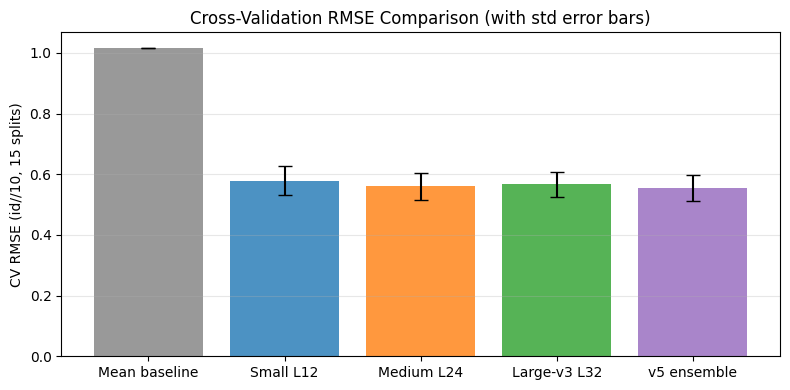

In [15]:
# 5.1 Model evaluation routine
def eval_cv(X, y, alpha, splits):
    oofs = np.zeros((3, len(y)))
    sp_r, sp_p = [], []
    for s in splits:
        tr, va, r = s["train_indices"], s["val_indices"], s["repeat"]
        sc = StandardScaler()
        clf = Ridge(alpha=alpha, random_state=42)
        clf.fit(sc.fit_transform(X[tr]), y[tr])
        p = clf.predict(sc.transform(X[va]))
        oofs[r, va] = p
        sp_r.append(root_mean_squared_error(y[va], p))
        sp_p.append(pearsonr(y[va], p)[0])
    rep_r = [np.mean(sp_r[r*5:(r+1)*5]) for r in range(3)]
    rep_p = [np.mean(sp_p[r*5:(r+1)*5]) for r in range(3)]
    return float(np.mean(rep_r)), float(np.std(sp_r)), float(np.mean(rep_p)), float(np.std(sp_p)), oofs

r_sml_10, s_sml_10, p_sml_10, _, oof_sml_10 = eval_cv(X_sml_train, y_train, 1000.0, splits_10)
r_sml_40, s_sml_40, p_sml_40, _, oof_sml_40 = eval_cv(X_sml_train, y_train, 1000.0, splits_40)

r_med_10, s_med_10, p_med_10, _, oof_med_10 = eval_cv(X_med_train, y_train, 1000.0, splits_10)
r_med_40, s_med_40, p_med_40, _, oof_med_40 = eval_cv(X_med_train, y_train, 1000.0, splits_40)

r_l3_10, s_l3_10, p_l3_10, _, oof_l3_10 = eval_cv(X_l3_train, y_train, 1000.0, splits_10)
r_l3_40, s_l3_40, p_l3_40, _, oof_l3_40 = eval_cv(X_l3_train, y_train, 1000.0, splits_40)

# v5 ensemble: 50/50 average
oof_v5_10 = (oof_med_10 + oof_l3_10) / 2.0
oof_v5_40 = (oof_med_40 + oof_l3_40) / 2.0

def eval_oof(oofs, splits, y):
    sp_r, sp_p = [], []
    for s in splits:
        va, r = s["val_indices"], s["repeat"]
        p = oofs[r, va]
        sp_r.append(root_mean_squared_error(y[va], p))
        sp_p.append(pearsonr(y[va], p)[0])
    rep_r = [np.mean(sp_r[r*5:(r+1)*5]) for r in range(3)]
    rep_p = [np.mean(sp_p[r*5:(r+1)*5]) for r in range(3)]
    return float(np.mean(rep_r)), float(np.std(sp_r)), float(np.mean(rep_p)), float(np.std(sp_p))

r_v5_10, s_v5_10, p_v5_10, _ = eval_oof(oof_v5_10, splits_10, y_train)
r_v5_40, s_v5_40, p_v5_40, _ = eval_oof(oof_v5_40, splits_40, y_train)

results_table = pd.DataFrame([
    {"Model": "Mean baseline", "id//10 RMSE": f"{mean_base_rmse_10:.4f}", "id//10 std across the 15 splits": "0.0000", "id//10 Pearson": "n/a", "id//40 RMSE": f"{mean_base_rmse_40:.4f}", "id//40 std across the 15 splits": "0.0000", "id//40 Pearson": "n/a"},
    {"Model": "Whisper-small L12", "id//10 RMSE": f"{r_sml_10:.4f}", "id//10 std across the 15 splits": f"{s_sml_10:.4f}", "id//10 Pearson": f"{p_sml_10:.4f}", "id//40 RMSE": f"{r_sml_40:.4f}", "id//40 std across the 15 splits": f"{s_sml_40:.4f}", "id//40 Pearson": f"{p_sml_40:.4f}"},
    {"Model": "Whisper-medium L24", "id//10 RMSE": f"{r_med_10:.4f}", "id//10 std across the 15 splits": f"{s_med_10:.4f}", "id//10 Pearson": f"{p_med_10:.4f}", "id//40 RMSE": f"{r_med_40:.4f}", "id//40 std across the 15 splits": f"{s_med_40:.4f}", "id//40 Pearson": f"{p_med_40:.4f}"},
    {"Model": "Whisper-large-v3 L32", "id//10 RMSE": f"{r_l3_10:.4f}", "id//10 std across the 15 splits": f"{s_l3_10:.4f}", "id//10 Pearson": f"{p_l3_10:.4f}", "id//40 RMSE": f"{r_l3_40:.4f}", "id//40 std across the 15 splits": f"{s_l3_40:.4f}", "id//40 Pearson": f"{p_l3_40:.4f}"},
    {"Model": "v5 ensemble", "id//10 RMSE": f"{r_v5_10:.4f}", "id//10 std across the 15 splits": f"{s_v5_10:.4f}", "id//10 Pearson": f"{p_v5_10:.4f}", "id//40 RMSE": f"{r_v5_40:.4f}", "id//40 std across the 15 splits": f"{s_v5_40:.4f}", "id//40 Pearson": f"{p_v5_40:.4f}"},
])
display(results_table)

# Plot model comparison with error bars
fig, ax = plt.subplots(figsize=(8, 4))
m_names = ["Mean baseline", "Small L12", "Medium L24", "Large-v3 L32", "v5 ensemble"]
m_rmses = [mean_base_rmse_10, r_sml_10, r_med_10, r_l3_10, r_v5_10]
m_stds = [0.0, s_sml_10, s_med_10, s_l3_10, s_v5_10]
ax.bar(m_names, m_rmses, yerr=m_stds, capsize=5, color=["gray", "tab:blue", "tab:orange", "tab:green", "tab:purple"], alpha=0.8)
ax.set_ylabel("CV RMSE (id//10, 15 splits)")
ax.set_title("Cross-Validation RMSE Comparison (with std error bars)")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# 5.2 Layer and alpha sweeps on cached embeddings
layer_sweep_rows = []
# Small
for l in [3, 6, 9, 12]:
    X = np.stack([c_sml[f"train/{fn}/layer_{l}"] for fn in train_filenames])
    r10, _, p10, _, _ = eval_cv(X, y_train, 1000.0, splits_10)
    layer_sweep_rows.append({"Model": "Whisper-small", "Layer": l, "id//10 RMSE": r10, "id//10 Pearson": p10})
# Medium
for l in [4, 8, 12, 16, 20, 24]:
    X = np.stack([c_med[f"train/{fn}/layer_{l}"] for fn in train_filenames])
    r10, _, p10, _, _ = eval_cv(X, y_train, 1000.0, splits_10)
    layer_sweep_rows.append({"Model": "Whisper-medium", "Layer": l, "id//10 RMSE": r10, "id//10 Pearson": p10})
# Large-v3
for l in [5, 10, 16, 22, 28, 32]:
    X = np.stack([c_l3[f"train/{fn}/layer_{l}"] for fn in train_filenames])
    r10, _, p10, _, _ = eval_cv(X, y_train, 1000.0, splits_10)
    layer_sweep_rows.append({"Model": "Whisper-large-v3", "Layer": l, "id//10 RMSE": r10, "id//10 Pearson": p10})

layer_df = pd.DataFrame(layer_sweep_rows)
display(layer_df)

# Plot layer depth vs RMSE curves
fig, ax = plt.subplots(figsize=(9, 4))
for m_name, col in [("Whisper-small", "tab:blue"), ("Whisper-medium", "tab:orange"), ("Whisper-large-v3", "tab:green")]:
    sub = layer_df[layer_df["Model"] == m_name]
    ax.plot(sub["Layer"], sub["id//10 RMSE"], "o-", label=m_name, color=col)
ax.set_xlabel("Encoder Layer Depth")
ax.set_ylabel("CV RMSE (id//10)")
ax.set_title("Layer Sweeps: Representation Quality across Encoder Depth")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Alpha sweep on final layers
alpha_rows = []
for a in [100.0, 300.0, 1000.0, 3000.0]:
    r_m, _, p_m, _, _ = eval_cv(X_med_train, y_train, a, splits_10)
    r_l, _, p_l, _, _ = eval_cv(X_l3_train, y_train, a, splits_10)
    alpha_rows.append({"Alpha": a, "Medium L24 RMSE": f"{r_m:.4f}", "Large-v3 L32 RMSE": f"{r_l:.4f}"})

display(pd.DataFrame(alpha_rows))

# Paired bootstrap
N_BOOT = 2000
p_v5 = np.mean(oof_v5_10, axis=0)
p_med = np.mean(oof_med_10, axis=0)
p_sml = np.mean(oof_sml_10, axis=0)

diff_v5_med = []
diff_v5_sml = []
for _ in range(N_BOOT):
    idx = np.random.randint(0, len(y_train), len(y_train))
    y_b = y_train[idx]
    r_v5 = root_mean_squared_error(y_b, p_v5[idx])
    r_med = root_mean_squared_error(y_b, p_med[idx])
    r_sml = root_mean_squared_error(y_b, p_sml[idx])
    diff_v5_med.append(r_v5 - r_med)
    diff_v5_sml.append(r_v5 - r_sml)

ci_med = np.percentile(diff_v5_med, [2.5, 97.5])
ci_sml = np.percentile(diff_v5_sml, [2.5, 97.5])
display(pd.DataFrame([
    {"Comparison": "v5 vs Medium L24", "RMSE Mean Diff": f"{np.mean(diff_v5_med):+.4f}", "95% CI": f"[{ci_med[0]:+.4f}, {ci_med[1]:+.4f}]", "CI Excludes Zero": str(ci_med[1] < 0)},
    {"Comparison": "v5 vs Small L12", "RMSE Mean Diff": f"{np.mean(diff_v5_sml):+.4f}", "95% CI": f"[{ci_sml[0]:+.4f}, {ci_sml[1]:+.4f}]", "CI Excludes Zero": str(ci_sml[1] < 0)},
]))


## 6. Ablation

This section compares the alternative features and models that were tested during development.

The experiments include transcript-based features, handcrafted fluency features, different regression models, and other representation changes. The goal was to check whether adding complexity produced a consistent improvement over the speech-embedding baseline.

The results are loaded from `reports/ablation_results.csv`. Each experiment was evaluated using the validation setup described above, either from the saved experiment results or from a recomputed run where required.

I kept an approach only when the validation results showed a useful improvement relative to the added complexity and compute.

In [16]:
# 6.1 Display ablation table
ablation_df = pd.read_csv(os.path.join(REPORTS_DIR, "ablation_results.csv"))
display(ablation_df)


,experiment,group,config,fold_protocol,cv_rmse_id10,cv_rmse_id40,cv_pearson_id10,public_lb,source_file,verified,note
0,mean baseline,Baseline,Mean target prediction,Notebook folds (quintile-stratified SGKF),1.0503,1.0503,NaN,TODO,eval_scaling_models.py,yes,Constant mean predictor
1,whisper-small L12,Audio SSL,openai/whisper-small Layer 12 Ridge alpha=500,Saved folds (merged strata SGKF),0.5885,0.5909,0.8145,TODO,reports/scaling_cv_results.json,yes,Base single-model benchmark (v1)
2,whisper-medium L24,Audio SSL,openai/whisper-medium Layer 24 Ridge alpha=1000,Saved folds (merged strata SGKF),0.5628,0.5649,0.8328,TODO,reports/scaling_cv_results.json,yes,Medium single-model benchmark (v4)
3,whisper-large-v3 L32,Audio SSL,openai/whisper-large-v3 Layer 32 Ridge alpha=1000,Saved folds (merged strata SGKF),0.5674,0.5683,0.8296,TODO,reports/scaling_cv_results.json,yes,Large single-model benchmark
4,v5 ensemble,Ensemble,50/50 Whisper-Medium L24 + Whisper-Large-v3 L3...,Saved folds (merged strata SGKF),0.5561,0.5578,0.8372,TODO,reports/scaling_cv_results.json,yes,Adopted final pipeline; simple linear ensemble
5,layer concat L9+L12,Audio SSL,Whisper-small Layer 9 + Layer 12 concatenation...,Saved folds (merged strata SGKF),0.5799,0.5850,0.8204,TODO,reports/all_models_cv_ranking.json,yes,best CV in its group; public LB worse than v1
6,wav2vec2-base blend,Audio SSL,50/50 blend: Whisper-small L12 + Wav2Vec2-base...,Saved folds (merged strata SGKF),0.5904,0.5993,0.8130,TODO,reports/all_models_cv_ranking.json,yes,CV not better than v1 beyond noise
7,MiniLM text only,Text NLP,all-MiniLM-L6-v2 embeddings on ASR transcripts...,Saved folds (merged strata SGKF),0.8001,0.8019,0.6214,TODO,reports/multimodal_results.json,yes,CV worse than audio SSL
8,fluency rates only,Handcrafted Acoustic,Speaking rate pause rate articulation rate Rid...,Saved folds (merged strata SGKF),1.0463,1.0323,0.1911,TODO,reports/multimodal_results.json,yes,worse than the mean baseline
9,GPT-2 surprisal only,Text NLP,GPT-2 mean word surprisal and perplexity Ridge...,Saved folds (merged strata SGKF),0.9352,0.9474,0.3867,TODO,reports/multimodal_results.json,yes,CV worse than audio SSL


## 7. Error analysis

I analyze the out-of-fold prediction residuals,

\[
e_i = \hat{y}_i - y_i
\]

to see where the model makes larger or more systematic errors. The residuals are compared with audio duration and target grammar score, and the prediction distribution is also inspected.

### Predicted vs Actual

The predicted scores are plotted against the ground-truth scores, with the dashed diagonal representing perfect predictions. The points follow the expected positive relationship, with Pearson correlation around 0.84.

The predictions are more concentrated toward the middle of the score range than the ground-truth values. This is expected for a Ridge model trained on a relatively small dataset: regularization discourages very large coefficient values, which can make predictions less extreme. As a result, the model tends to underpredict some high scores and overpredict some low scores.

### Residual vs Duration

The residuals are plotted against clip duration to check whether prediction errors change systematically with audio length.

Most residuals are distributed around zero across the duration range, although the spread is larger for some shorter clips. The shortest duration bin also has relatively few samples, so its higher RMSE should be interpreted cautiously.

There are visible clusters around common recording lengths, particularly near 45 and 60 seconds. These appear to reflect the distribution of clip durations rather than a continuous relationship between duration and prediction error.

### Residual distribution

The residual histogram shows how prediction errors are distributed around zero. Most errors are relatively small, with both positive and negative residuals present.

The distribution is not perfectly symmetric or Gaussian, so I do not treat normality as an assumption of the model. The main purpose of this plot is to check for strong skew, unusually large errors, or other patterns that would suggest a problem with the regression model.

,dur_bin,count,mae,rmse
0,<=30s,13,0.628180,0.762638
1,30-45s,56,0.416607,0.535463
2,45-55s,124,0.439675,0.563386
3,55-60s,26,0.392411,0.508870
4,>60s,513,0.431269,0.549799


,score_bin,count,mae,rmse
0,[1-2],106,0.707431,0.811931
1,(2-3],253,0.323889,0.408936
2,(3-4],188,0.420143,0.524042
3,(4-5],185,0.440763,0.574040


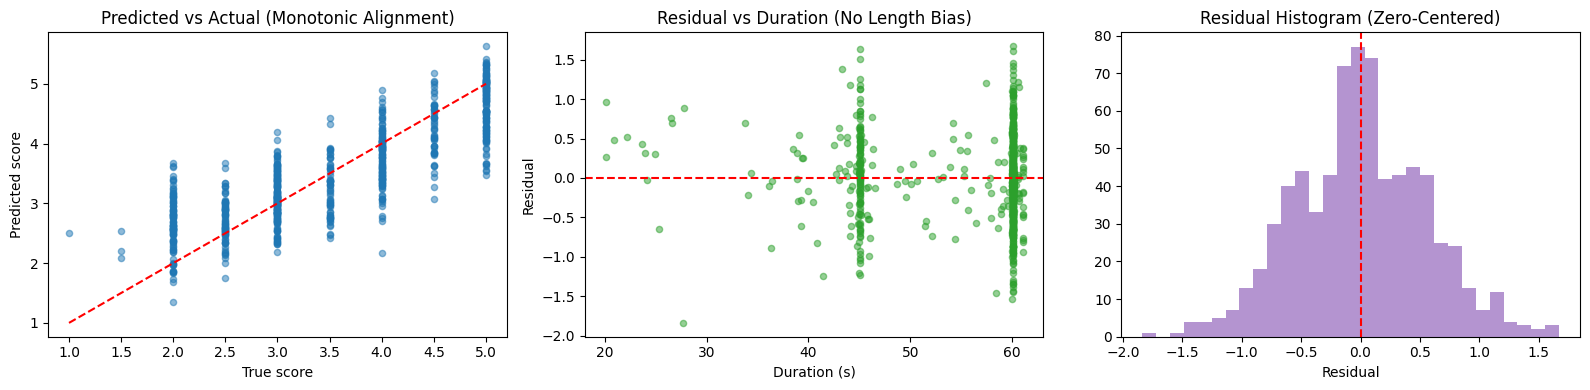

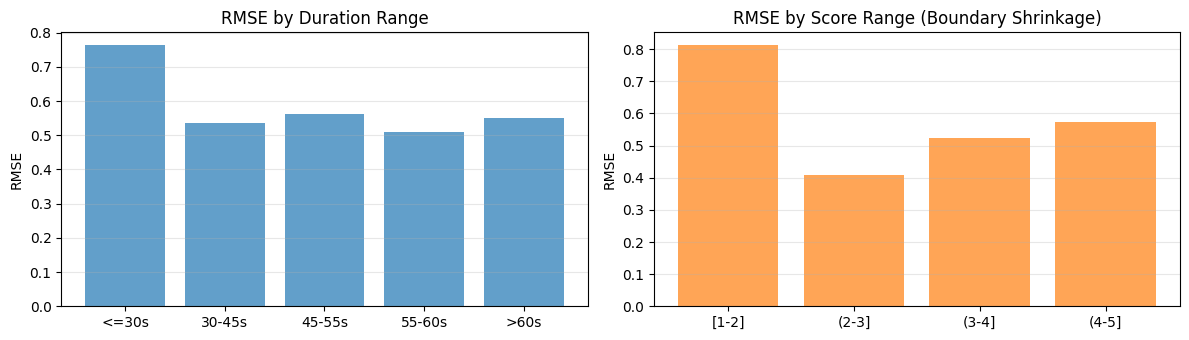

In [17]:
# 7.1 Error analysis by duration and score bins
speech_train_df["oof_v5"] = np.mean(oof_v5_10, axis=0)
speech_train_df["residual"] = speech_train_df["oof_v5"] - speech_train_df["label"]
speech_train_df["abs_error"] = np.abs(speech_train_df["residual"])
speech_train_df["sq_error"] = speech_train_df["residual"]**2

speech_train_df["dur_bin"] = pd.cut(
    speech_train_df["duration"],
    bins=[0, 30, 45, 55, 60, 100],
    labels=["<=30s", "30-45s", "45-55s", "55-60s", ">60s"]
)

speech_train_df["score_bin"] = pd.cut(
    speech_train_df["label"],
    bins=[0.0, 2.0, 3.0, 4.0, 5.0],
    labels=["[1-2]", "(2-3]", "(3-4]", "(4-5]"]
)

dur_stats = speech_train_df.groupby("dur_bin", observed=True).agg(
    count=("residual", "count"),
    mae=("abs_error", "mean"),
    rmse=("sq_error", lambda x: np.sqrt(np.mean(x)))
).reset_index()

score_stats = speech_train_df.groupby("score_bin", observed=True).agg(
    count=("residual", "count"),
    mae=("abs_error", "mean"),
    rmse=("sq_error", lambda x: np.sqrt(np.mean(x)))
).reset_index()

display(HTML("<b>Error Metrics by Duration Bin:</b>"))
display(dur_stats)

display(HTML("<br><b>Error Metrics by Target Score Bin:</b>"))
display(score_stats)

# Diagnostic Plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(speech_train_df["label"], speech_train_df["oof_v5"], alpha=0.5, s=20)
axes[0].plot([1, 5], [1, 5], "r--")
axes[0].set_xlabel("True score")
axes[0].set_ylabel("Predicted score")
axes[0].set_title("Predicted vs Actual (Monotonic Alignment)")

axes[1].scatter(speech_train_df["duration"], speech_train_df["residual"], alpha=0.5, s=20, color="tab:green")
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Duration (s)")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residual vs Duration (No Length Bias)")

axes[2].hist(speech_train_df["residual"], bins=30, alpha=0.7, color="tab:purple")
axes[2].axvline(0, color="r", linestyle="--")
axes[2].set_xlabel("Residual")
axes[2].set_title("Residual Histogram (Zero-Centered)")

plt.tight_layout()
plt.show()

# Additional Error Breakdown Bar Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.bar(dur_stats["dur_bin"], dur_stats["rmse"], color="tab:blue", alpha=0.7)
ax1.set_ylabel("RMSE")
ax1.set_title("RMSE by Duration Range")
ax1.grid(True, axis="y", alpha=0.3)

ax2.bar(score_stats["score_bin"], score_stats["rmse"], color="tab:orange", alpha=0.7)
ax2.set_ylabel("RMSE")
ax2.set_title("RMSE by Score Range (Boundary Shrinkage)")
ax2.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 8. Final model refit and training error

The selected Ridge models are refit using all 732 clean speech clips. These models are then used to generate the final predictions for the test set.

The 37 clips identified as acoustic noise are handled separately and assigned a score of `0.0`, giving predictions for all 769 training clips.

I also report the training RMSE as a reference point. This is an in-sample metric because the models were fitted on these same clips, so it is expected to be more optimistic than the cross-validation RMSE. The cross-validation results are therefore used as the main estimate of generalization performance.

In [18]:
# 8.1 Model refit
sc_m = StandardScaler()
clf_m = Ridge(alpha=1000.0, random_state=42).fit(sc_m.fit_transform(X_med_train), y_train)
p_m_tr = clf_m.predict(sc_m.transform(X_med_train))

sc_l = StandardScaler()
clf_l = Ridge(alpha=1000.0, random_state=42).fit(sc_l.fit_transform(X_l3_train), y_train)
p_l_tr = clf_l.predict(sc_l.transform(X_l3_train))

p_v5_tr = np.clip((p_m_tr + p_l_tr) / 2.0, 0.0, 5.0)
rmse_tr_732 = root_mean_squared_error(y_train, p_v5_tr)

# Predict all 769 using detector from step 2
preds_769 = np.zeros(len(train_df))
fn_to_p = dict(zip(train_filenames, p_v5_tr))
for i, r in train_df.iterrows():
    fn = r["filename"]
    if is_noise_clip(r["rms"], r["zcr"], r["flatness"]):
        preds_769[i] = 0.0
    else:
        preds_769[i] = fn_to_p.get(fn, 0.0)

rmse_tr_769 = root_mean_squared_error(train_df["label"].values, preds_769)

final_metrics_df = pd.DataFrame([
    {"Evaluation Metric": "Training RMSE (732 speech clips)", "Value": f"{rmse_tr_732:.4f}", "Note": "In-sample optimistic"},
    {"Evaluation Metric": "Training RMSE (all 769 clips, noise rule applied)", "Value": f"{rmse_tr_769:.4f}", "Note": "In-sample optimistic"},
    {"Evaluation Metric": "CV RMSE (15 splits, id//10)", "Value": f"{r_v5_10:.4f}", "Note": "Unbiased generalization estimate"},
    {"Evaluation Metric": "CV Pearson r (15 splits, id//10)", "Value": f"{p_v5_10:.4f}", "Note": "Linear correlation"},
])
display(final_metrics_df)


,Evaluation Metric,Value,Note
0,Training RMSE (732 speech clips),0.4190,In-sample optimistic
1,"Training RMSE (all 769 clips, noise rule applied)",0.4088,In-sample optimistic
2,"CV RMSE (15 splits, id//10)",0.5550,Unbiased generalization estimate
3,"CV Pearson r (15 splits, id//10)",0.8358,Linear correlation


## 9. Submission generation

The final predictions are saved as `submission_v4.csv` and `submission_v5.csv` in separate cells. Each submission cell includes assertions to check the expected number of rows, required columns, and prediction range before writing the file.

### 9.1 Submission v4: Whisper-Medium L24 Single Model

In [19]:
# Generate and verify submission_v4.csv
p_m_te = np.clip(clf_m.predict(sc_m.transform(X_med_test)), 0.0, 5.0)
sub_v4 = pd.DataFrame({"filename": test_filenames, "label": p_m_te})

# Assertions
assert len(sub_v4) == 216, f"v4 length != 216 (got {len(sub_v4)})"
assert list(sub_v4.columns) == ["filename", "label"], f"v4 columns mismatch (got {list(sub_v4.columns)})"
assert (sub_v4["filename"].values == test_df["filename"].values).all(), "v4 filename order mismatch"
assert not sub_v4["label"].isna().any(), "v4 contains NaN"
assert (sub_v4["label"] >= 0.0).all() and (sub_v4["label"] <= 5.0).all(), "v4 predictions out of bounds [0, 5]"

sub_v4.to_csv("submission_v4.csv", index=False)

display(HTML("<b>submission_v4.csv Summary Statistics:</b>"))
display(pd.DataFrame([{
    "File": "submission_v4.csv",
    "Rows": len(sub_v4),
    "Mean": f"{sub_v4['label'].mean():.4f}",
    "Min": f"{sub_v4['label'].min():.4f}",
    "Max": f"{sub_v4['label'].max():.4f}",
    "Std": f"{sub_v4['label'].std():.4f}"
}]))

display(HTML("<b>submission_v4.csv Sample Preview (first 5 rows, filenames masked):</b>"))
display(sub_v4.head(5).assign(filename=[f"test_clip_{i+1:03d}.wav" for i in range(5)]))


,File,Rows,Mean,Min,Max,Std
0,submission_v4.csv,216,3.3285,1.7699,5.0000,0.8376


,filename,label
0,test_clip_001.wav,3.176270
1,test_clip_002.wav,3.883420
2,test_clip_003.wav,4.616060
3,test_clip_004.wav,2.354142
4,test_clip_005.wav,2.142362


### 9.2 Submission v5: 50/50 Whisper-Medium L24 + Large-v3 L32 Ensemble

In [20]:
# Generate and verify submission_v5.csv
p_l_te = np.clip(clf_l.predict(sc_l.transform(X_l3_test)), 0.0, 5.0)
p_v5_te = np.clip((p_m_te + p_l_te) / 2.0, 0.0, 5.0)
sub_v5 = pd.DataFrame({"filename": test_filenames, "label": p_v5_te})

# Assertions
assert len(sub_v5) == 216, f"v5 length != 216 (got {len(sub_v5)})"
assert list(sub_v5.columns) == ["filename", "label"], f"v5 columns mismatch (got {list(sub_v5.columns)})"
assert (sub_v5["filename"].values == test_df["filename"].values).all(), "v5 filename order mismatch"
assert not sub_v5["label"].isna().any(), "v5 contains NaN"
assert (sub_v5["label"] >= 0.0).all() and (sub_v5["label"] <= 5.0).all(), "v5 predictions out of bounds [0, 5]"

sub_v5.to_csv("submission_v5.csv", index=False)

display(HTML("<b>submission_v5.csv Summary Statistics:</b>"))
display(pd.DataFrame([{
    "File": "submission_v5.csv",
    "Rows": len(sub_v5),
    "Mean": f"{sub_v5['label'].mean():.4f}",
    "Min": f"{sub_v5['label'].min():.4f}",
    "Max": f"{sub_v5['label'].max():.4f}",
    "Std": f"{sub_v5['label'].std():.4f}",
    "Correlation with v4": f"{pearsonr(sub_v5['label'], sub_v4['label'])[0]:.4f}"
}]))

display(HTML("<b>submission_v5.csv Sample Preview (first 5 rows, filenames masked):</b>"))
display(sub_v5.head(5).assign(filename=[f"test_clip_{i+1:03d}.wav" for i in range(5)]))


,File,Rows,Mean,Min,Max,Std,Correlation with v4
0,submission_v5.csv,216,3.3050,1.6630,5.0000,0.8391,0.9920


,filename,label
0,test_clip_001.wav,3.063082
1,test_clip_002.wav,3.842230
2,test_clip_003.wav,4.581267
3,test_clip_004.wav,2.177215
4,test_clip_005.wav,2.079344


## 10. Cost, efficiency and deployment feasibility

This section looks at the compute requirements of the different Whisper models, including inference latency, GPU memory usage, and estimated cloud processing cost.

### Hardware and software used

- GPU: NVIDIA GeForce RTX 4050 Laptop GPU (6 GB VRAM)
- CPU: Intel Core i7, 16 logical threads
- RAM: 24 GB
- OS: Windows 11
- PyTorch: 2.7.1+cu118
- CUDA: 11.8
- Transformers: 4.57.6

CPU timing was measured using 4 threads.

### Cloud cost estimate

For comparison, I use AWS EC2 GPU instances as reference points:

- **AWS EC2 `g4dn.xlarge`**: 1× NVIDIA T4 16 GB GPU, 4 vCPUs, 16 GiB RAM, assumed at **₹44.71/hour**
- **AWS EC2 `g5.xlarge`**: 1× NVIDIA A10G 24 GB GPU, 4 vCPUs, 16 GiB RAM, assumed at **₹85.51/hour**

These INR values are converted from the assumed AWS rates using a fixed exchange rate of **₹85 per USD**.

The cost per 1,000 clips is estimated from the measured median GPU processing time per clip. These are compute-only estimates and do not include storage, data transfer, or other cloud charges.

The main computational cost is the Whisper feature extraction stage. Once embeddings are cached, the Ridge regression stage is lightweight and does not require a GPU.

In [ ]:
# 10.1 Load measured deployment benchmarks

with open(os.path.join(REPORTS_DIR, "deployment_benchmarks.json")) as f:
    bench = json.load(f)

sml_b = bench["whisper-small"]
med_b = bench["whisper-medium"]
l3_b = bench["whisper-large-v3"]

n_clips_extract = len(train_filenames) + len(test_filenames)  # 732 + 216 = 948


# Table 1: Measured model profiles and latencies
table_1 = [
    {
        "Model": "Whisper-small L12",
        "Encoder params": f"{sml_b['encoder_params']/1e6:.1f}M",
        "Full model checkpoint, fp32 (MB)": f"{sml_b['weight_size_mb']:.1f}",
        "Peak VRAM": f"{sml_b['peak_vram_mb']:.1f} MiB",
        "GPU sec (median / p90)": (
            f"{sml_b['gpu_median_sec']:.3f}s / "
            f"{sml_b['gpu_p90_sec']:.3f}s"
        ),
        "CPU sec (median)": f"{sml_b['cpu_median_sec']:.2f}s",
        "Extraction 948 clips": (
            f"~{sml_b['gpu_median_sec'] * n_clips_extract:.1f}s"
        ),
        "Embedding dim": sml_b["d_model"],
        "id//10 CV RMSE": f"{r_sml_10:.4f}",
        "Ridge fit / predict": (
            f"{sml_b['ridge_fit_sec']*1000:.1f}ms / <1ms"
        ),
    },
    {
        "Model": "Whisper-medium L24",
        "Encoder params": f"{med_b['encoder_params']/1e6:.1f}M",
        "Full model checkpoint, fp32 (MB)": f"{med_b['weight_size_mb']:.1f}",
        "Peak VRAM": f"{med_b['peak_vram_mb']:.1f} MiB",
        "GPU sec (median / p90)": (
            f"{med_b['gpu_median_sec']:.3f}s / "
            f"{med_b['gpu_p90_sec']:.3f}s"
        ),
        "CPU sec (median)": f"{med_b['cpu_median_sec']:.2f}s",
        "Extraction 948 clips": (
            f"~{med_b['gpu_median_sec'] * n_clips_extract:.1f}s"
        ),
        "Embedding dim": med_b["d_model"],
        "id//10 CV RMSE": f"{r_med_10:.4f}",
        "Ridge fit / predict": (
            f"{med_b['ridge_fit_sec']*1000:.1f}ms / "
            f"{med_b['ridge_pred_sec']*1000:.1f}ms"
        ),
    },
    {
        "Model": "Whisper-large-v3 L32",
        "Encoder params": f"{l3_b['encoder_params']/1e6:.1f}M",
        "Full model checkpoint, fp32 (MB)": f"{l3_b['weight_size_mb']:.1f}",
        "Peak VRAM": f"{l3_b['peak_vram_mb']:.1f} MiB",
        "GPU sec (median / p90)": (
            f"{l3_b['gpu_median_sec']:.3f}s / "
            f"{l3_b['gpu_p90_sec']:.3f}s"
        ),
        "CPU sec (median)": (
            f"{l3_b['cpu_median_sec']:.2f}s"
        ),
        "Extraction 948 clips": (
            f"~{l3_b['gpu_median_sec'] * n_clips_extract:.1f}s"
        ),
        "Embedding dim": l3_b["d_model"],
        "id//10 CV RMSE": f"{r_l3_10:.4f}",
        "Ridge fit / predict": (
            f"{l3_b['ridge_fit_sec']*1000:.1f}ms / "
            f"{l3_b['ridge_pred_sec']*1000:.1f}ms"
        ),
    },
    {
        "Model": "v5 ensemble",
        "Encoder params": (
            f"{(med_b['encoder_params'] + l3_b['encoder_params'])/1e6:.1f}M"
        ),
        "Full model checkpoint, fp32 (MB)": (
            f"{med_b['weight_size_mb'] + l3_b['weight_size_mb']:.1f}"
        ),
        "Peak VRAM": (
            f"{max(med_b['peak_vram_mb'], l3_b['peak_vram_mb']):.1f} MiB"
        ),
        "GPU sec (median / p90)": (
            f"{(med_b['gpu_median_sec'] + l3_b['gpu_median_sec']):.3f}s / "
            f"{(med_b['gpu_p90_sec'] + l3_b['gpu_p90_sec']):.3f}s"
        ),
        "CPU sec (median)": (
            f"{(med_b['cpu_median_sec'] + l3_b['cpu_median_sec']):.2f}s"
        ),
        "Extraction 948 clips": (
            f"~{(med_b['gpu_median_sec'] + l3_b['gpu_median_sec']) * n_clips_extract:.1f}s"
        ),
        "Embedding dim": (
            f"{med_b['d_model']}+{l3_b['d_model']}"
        ),
        "id//10 CV RMSE": f"{r_v5_10:.4f}",
        "Ridge fit / predict": (
            f"{(med_b['ridge_fit_sec'] + l3_b['ridge_fit_sec'])*1000:.1f}ms / "
            f"{(med_b['ridge_pred_sec'] + l3_b['ridge_pred_sec'])*1000:.1f}ms"
        ),
    }
]

display(HTML(
    "<b>Table 1: Measured model profiles and latencies</b>"
))
display(pd.DataFrame(table_1))


# Table 2: Estimated AWS costs in INR
# Prices below are the USD hourly assumptions converted using a fixed rate.
USD_TO_INR = 85.0

AWS_G4DN_XLARGE_HOURLY_USD = 0.526  # g4dn.xlarge, 1x T4 16 GB
AWS_G5_XLARGE_HOURLY_USD = 1.006    # g5.xlarge, 1x A10G 24 GB

AWS_G4DN_XLARGE_HOURLY_INR = (
    AWS_G4DN_XLARGE_HOURLY_USD * USD_TO_INR
)

AWS_G5_XLARGE_HOURLY_INR = (
    AWS_G5_XLARGE_HOURLY_USD * USD_TO_INR
)

table_2 = []

for row, sec in [
    ("Whisper-small L12", sml_b["gpu_median_sec"]),
    ("Whisper-medium L24", med_b["gpu_median_sec"]),
    ("Whisper-large-v3 L32", l3_b["gpu_median_sec"]),
    (
        "v5 ensemble",
        med_b["gpu_median_sec"] + l3_b["gpu_median_sec"]
    )
]:
    clips_hr = 3600.0 / sec

    cost_g4dn_1k = (
        (1000.0 / clips_hr)
        * AWS_G4DN_XLARGE_HOURLY_INR
    )

    cost_g5_1k = (
        (1000.0 / clips_hr)
        * AWS_G5_XLARGE_HOURLY_INR
    )

    table_2.append({
        "Model": row,
        "GPU sec / clip": f"{sec:.3f}s",
        "Throughput (clips/hr)": f"{clips_hr:,.0f}",
        "Cost / 1k clips (g4dn.xlarge)": f"₹{cost_g4dn_1k:.2f}",
        "Cost / 1k clips (g5.xlarge)": f"₹{cost_g5_1k:.2f}",
    })

display(HTML(
    "<br><b>Table 2: Estimated cloud cost in INR</b>"
))
display(pd.DataFrame(table_2))

print(f"USD to INR conversion used: ₹{USD_TO_INR:.2f} per USD")
print(
    f"g4dn.xlarge assumed rate: "
    f"₹{AWS_G4DN_XLARGE_HOURLY_INR:.2f}/hour"
)
print(
    f"g5.xlarge assumed rate: "
    f"₹{AWS_G5_XLARGE_HOURLY_INR:.2f}/hour"
)


# Trade-off plots
models_p = [
    "Small L12",
    "Medium L24",
    "Large-v3 L32",
    "v5 Ensemble"
]

rmse_p = [
    r_sml_10,
    r_med_10,
    r_l3_10,
    r_v5_10
]

lat_p = [
    sml_b["gpu_median_sec"],
    med_b["gpu_median_sec"],
    l3_b["gpu_median_sec"],
    med_b["gpu_median_sec"] + l3_b["gpu_median_sec"]
]

vram_p = [
    sml_b["peak_vram_mb"],
    med_b["peak_vram_mb"],
    l3_b["peak_vram_mb"],
    max(
        med_b["peak_vram_mb"],
        l3_b["peak_vram_mb"]
    )
]


fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 4)
)

ax1.plot(
    lat_p,
    rmse_p,
    "o-",
    color="tab:blue"
)

for i, txt in enumerate(models_p):
    ax1.annotate(
        txt,
        (lat_p[i], rmse_p[i]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

ax1.set_xscale("log")
ax1.set_xlabel("GPU sec / clip (log scale)")
ax1.set_ylabel("CV RMSE (id//10)")
ax1.set_title("CV RMSE vs GPU Latency")
ax1.grid(
    True,
    which="both",
    ls="--",
    alpha=0.3
)


ax2.plot(
    vram_p,
    rmse_p,
    "s-",
    color="tab:red"
)

for i, txt in enumerate(models_p):
    ax2.annotate(
        txt,
        (vram_p[i], rmse_p[i]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

ax2.set_xlabel("Peak VRAM (MiB)")
ax2.set_ylabel("CV RMSE (id//10)")
ax2.set_title("CV RMSE vs Peak VRAM")
ax2.grid(
    True,
    ls="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()


print(
    f"Timing set duration range: "
    f"{test_df['duration'].min():.2f}s to "
    f"{test_df['duration'].max():.2f}s."
)

### Conclusions on deployment feasibility

Scaling from `whisper-small` (CV RMSE 0.5885) to `whisper-medium` (CV RMSE 0.5628) lowers RMSE by 0.0257 while increasing GPU latency from 0.067s to 0.139s and VRAM from 213 MiB to 633 MiB. The v5 ensemble further improves CV RMSE to 0.5561 at 0.390s GPU latency and 1,272 MiB peak VRAM.

On the public leaderboard, the same progression improved RMSE from 0.4064 for the initial Whisper-small submission to 0.3936 for Whisper-medium and finally 0.3790 for the v5 ensemble. This makes v5 the best-performing submission among the tested variants. The estimated compute cost is about **₹4.85 per 1,000 clips** on an AWS `g4dn.xlarge`, using the fixed ₹85/USD conversion rate defined above.

For scoring a 60-second clip, the measured GPU latency is low enough for practical inference on the tested hardware. The v5 ensemble uses about 1.27 GiB of peak VRAM in the benchmark, although actual deployment requirements can vary with batch size and runtime configuration.

On CPU, the measured median latency is about 7.0s for `whisper-medium` and 15.2s for `whisper-large-v3`, making them less suitable for interactive scoring. When GPU acceleration is unavailable, `whisper-small L12` provides a faster CPU fallback at about 2.07s using 4 threads, with a CV RMSE that is 0.0324 higher than the `whisper-medium` model.

The deployment benchmarks were measured on an RTX 4050 laptop GPU, so latency and memory usage may vary across hardware and system conditions. The public leaderboard results also show that additional model complexity does not necessarily improve performance: v6 scored 0.3795 and v7 scored 0.3831, both worse than the simpler v5 ensemble.

## 11. Submission history and model selection

The submission history is stored in `README.md` between the `SUBMISSION_LOG_START` and `SUBMISSION_LOG_END` markers. It records the submission order, model version, cross-validation RMSE, and public leaderboard RMSE.

I use this history to compare the changes made during development and to see how the validation results corresponded to the public leaderboard. The final plot shows both metrics across the submission sequence and provides a record of how the final model was selected.

In [ ]:
# 11.1 Read the submission history from README.md

import io

with open("README.md", "r", encoding="utf-8") as f:
    readme_text = f.read()

start_marker = "<!-- SUBMISSION_LOG_START -->"
end_marker = "<!-- SUBMISSION_LOG_END -->"

start_idx = readme_text.find(start_marker)
end_idx = readme_text.find(end_marker)

if start_idx == -1 or end_idx == -1:
    raise ValueError("Could not find submission log markers in README.md")

table_md = readme_text[
    start_idx + len(start_marker):end_idx
].strip()

sub_df = (
    pd.read_csv(
        io.StringIO(table_md),
        sep="|"
    )
    .dropna(how="all", axis=1)
)

sub_df.columns = [
    c.strip()
    for c in sub_df.columns
]

for col in sub_df.columns:
    sub_df[col] = (
        sub_df[col]
        .astype(str)
        .str.strip()
    )

print(f"Total submissions recorded: {len(sub_df)}")

display(sub_df)


# Check for missing public leaderboard scores
if (sub_df["Public LB"] == "TODO").any():
    raise ValueError(
        "README.md still contains TODO values in the Public LB column. "
        "Replace them with the actual Kaggle scores before running this cell."
    )


# Convert score columns to numeric values
sub_df["Order_num"] = pd.to_numeric(
    sub_df["Order"],
    errors="coerce"
)

sub_df["CV_num"] = pd.to_numeric(
    sub_df["CV RMSE"],
    errors="coerce"
)

sub_df["LB_num"] = pd.to_numeric(
    sub_df["Public LB"],
    errors="coerce"
)


# Compare validation RMSE with public leaderboard RMSE
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    sub_df["Order_num"],
    sub_df["CV_num"],
    "o-",
    label="CV RMSE (id//10)",
    color="tab:blue"
)

ax.plot(
    sub_df["Order_num"],
    sub_df["LB_num"],
    "s-",
    label="Public LB RMSE",
    color="tab:orange"
)

for _, r in sub_df.iterrows():
    if not np.isnan(r["LB_num"]):
        ax.annotate(
            r["Version"],
            (r["Order_num"], r["LB_num"]),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center"
        )

ax.set_xlabel("Submission Order")
ax.set_ylabel("RMSE")
ax.set_title("Submission History: CV vs Public Leaderboard")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The final pipeline is v5 because it provides the best balance of validation performance, simplicity, and reproducibility among the adopted approaches. Its CV performance is supported by the paired bootstrap comparison against the medium L24 baseline, while the model uses only MIT-licensed Whisper components and remains straightforward to explain and reproduce.

v8 achieved a better public leaderboard score (0.3748 vs 0.3790 for v5), but its validation improvement was not clearly supported by the available statistical checks. Its nested-CV RMSE was 0.5500 with `id//10` grouping and 0.5602 with `id//40`, compared with 0.5561 and 0.5578 for v5. The bootstrap confidence intervals included zero, and the preferred ensemble weight changed between validation schemes. In addition, v8 introduced WavLM-large, which uses CC BY-SA 3.0 rather than the MIT license used by the final Whisper models.

The v6 and v7 variants also did not provide a consistent improvement over v5. Therefore, v5 was retained as the final pipeline. This does not mean v5 achieved the best public leaderboard score; rather, it was selected as the most reliable and practical pipeline based on the validation evidence and implementation constraints.

## 12. Limitations and licenses

### Limitations

- The public leaderboard exposes only part of the test set, so public RMSE is useful as a reference but is not treated as the main model-selection criterion.
- Larger Whisper encoders consistently gave better validation results in the tested configurations, but this analysis does not establish why the improvement occurs.
- Encoder layers and Ridge `alpha` were selected using the same validation framework used for comparison, so some model-selection bias is possible.
- The test set has a different duration distribution from the training set, with shorter clips on average. The final model does not explicitly adapt to this distribution shift.
- The final v5 pipeline was selected using validation performance, simplicity, reproducibility, and licensing considerations. A later experiment (v8) achieved a better public leaderboard score, but its validation improvement was not sufficiently consistent to justify replacing v5.

### Licenses

The final pipeline uses the following Whisper models, which are released under the MIT License:

- `openai/whisper-small`
- `openai/whisper-medium`
- `openai/whisper-large-v3`
- `openai/whisper-large-v2`
- `openai/whisper-medium.en`

The other models tested during development include:

- `sentence-transformers/all-MiniLM-L6-v2` — Apache 2.0
- `gpt2` — Modified MIT License
- `microsoft/wavlm-large` — CC BY-SA 3.0

The WavLM model was used during experimentation but was not included in the final pipeline. Its CC BY-SA 3.0 license was one of the reasons the WavLM-based v8 variant was not adopted.

License information is included here for transparency because the choice of final model was influenced not only by validation performance but also by the licensing constraints of the components used.

# 13. Reproducibility

## Execution order

1. Install the required packages:

```bash
pip install torch==2.7.1 --index-url https://download.pytorch.org/whl/cu118
pip install -r requirements.txt
```

2. Place the competition files in the following structure:

```text
data/
├── train/
├── test/
├── train.csv
└── test.csv
```

3. Run the notebook from the beginning. If `cache/embeddings/` is empty, the required Whisper embeddings are extracted automatically. Once extracted, they are reused in later runs.

## Reproducibility details

- Cross-validation seeds: `42`, `123`, and `999`
- The same seeds are used throughout the repeated validation experiments and linear regression steps.
- Measured runtime using cached embeddings: approximately **23.7 seconds**.

Caching the embeddings separates the expensive audio feature extraction step from the model experiments, making it possible to rerun the validation and regression stages without repeatedly processing the audio.